# 3. House Price Modeling

Compare regression pipelines for later property transactions using a chronological training, validation, and test split. This notebook verifies its source data, selects a model using validation MAE, evaluates the selected model on test, and saves a reproducible pipeline and reports. 

## 1. Imports, Paths and Run Settings

In [1]:
from pathlib import Path
from datetime import datetime, timezone
from importlib.metadata import version
import hashlib
import json
import platform
import sys
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sqlalchemy import text
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, median_absolute_error, r2_score
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / 'src/db.py').is_file() and (p / 'data/raw/kc_house_data.csv').is_file()),
    None
)
if ROOT is None:
    raise FileNotFoundError('Open the property_analytics root or its notebooks folder first.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.db import get_engine

REPORT_DIR = ROOT / 'reports/modeling'
MODEL_DIR = ROOT / 'models'

SEED = 42
N_JOBS = 2
TARGET = 'price'
VALIDATION_START = pd.Timestamp('2015-01-01')
TEST_START = pd.Timestamp('2015-03-01')
EXPECTED_ROWS = 21613
EXPECTED_SOURCE = '02d5580da2ef7f0dd69effdf68f59a5a6788fe4f55533dab3e9e035d4bd4586e'
PACKAGES = {name: version(name) for name in (
    'pandas', 
    'numpy', 
    'scikit-learn', 
    'joblib', 
    'matplotlib',
    'SQLAlchemy', 
    'psycopg', 
    'python-dotenv'
)}

def require(condition, message):
    if not condition:
        raise ValueError(message)

def sha256_file(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

def notebook_code_sha256():
    saved = json.loads((ROOT / 'notebooks/3_modeling.ipynb').read_text(encoding='utf-8'))
    sources = [''.join(c['source']) for c in saved['cells'] if c['cell_type'] == 'code']
    return hashlib.sha256(json.dumps(sources, ensure_ascii=False).encode('utf-8')).hexdigest()

STAGES = [
    'setup', 
    'evidence', 
    'data', 
    'features', 
    'split', 
    'pipelines',
    'validation', 
    'validation_diagnostics', 
    'importance', 
    'test',
    'test_diagnostics', 
    'export', 
    'prediction_example'
]
COMPLETED = {'setup'}

def begin_stage(name):
    index = STAGES.index(name)
    COMPLETED.difference_update(STAGES[index:])
    require(set(STAGES[:index]).issubset(COMPLETED),
            'An earlier stage is incomplete. Run the numbered cells in order.')

SAVED_CODE_SHA256 = notebook_code_sha256()
plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.max_columns', 20)
print('Project:', ROOT.name)
print('Python:', platform.python_version(), '| scikit-learn:', PACKAGES['scikit-learn'])

Project: property_analytics
Python: 3.10.9 | scikit-learn: 1.7.2


## 2. Check the Audit and Step 2 Evidence

In [2]:
begin_stage('evidence')
RAW_PATH = ROOT / 'data/raw/kc_house_data.csv'
REFERENCE_PATH = ROOT / 'data/reference/audit_clean_reference.csv'
AUDIT_PATH = ROOT / 'data/reference/audit_reference_manifest.json'
STEP2_PATH = ROOT / 'reports/sql_validation/validation_report.json'
audit_manifest = json.loads(AUDIT_PATH.read_text(encoding='utf-8'))
step2_report = json.loads(STEP2_PATH.read_text(encoding='utf-8'))

require(sha256_file(RAW_PATH) == audit_manifest['source_sha256'] == EXPECTED_SOURCE,
        'Raw CSV does not match this audited experiment.')
require(sha256_file(REFERENCE_PATH) == audit_manifest['reference_sha256'],
        'The clean reference file does not match its audit manifest.')
require(audit_manifest['row_count'] == EXPECTED_ROWS, 'Unexpected audit row count.')
required_step2_checks = {
    'reference_source_match', 
    'database_connection', 
    'schema_verified',
    'raw_cells_equal_csv', 
    'raw_quality_passed', 
    'duplicate_checks_match_python',
    'domain_checks_match_python', 
    'clean_summary_matches',
    'all_clean_cells_match_python', 
    'analytic_views_match_python'
}
checks = step2_report.get('checks', {})
require(step2_report.get('status') == 'passed_programmatic_checks'
        and required_step2_checks.issubset(checks)
        and all(value is True for value in checks.values()),
        'Step 2 has not passed all required checks. Rerun Step 2 first.')
require(step2_report.get('database') == 'property_analytics_database'
        and step2_report.get('source_sha256') == EXPECTED_SOURCE
        and step2_report.get('rows_compared') == EXPECTED_ROWS,
        'Step 2 report belongs to a different database or dataset.')
sql_hashes = {p.name: sha256_file(p) for p in sorted((ROOT / 'sql').glob('*.sql'))}
require(sql_hashes == step2_report.get('sql_sha256'),
        'SQL files changed since the Step 2 report. Verify them in Step 2 first.')
INPUT_HASHES = {
    'raw_csv': sha256_file(RAW_PATH), 'clean_reference': sha256_file(REFERENCE_PATH),
    'audit_manifest': sha256_file(AUDIT_PATH), 'step2_report': sha256_file(STEP2_PATH)
}
print('Source, reference, SQL hashes and saved checks: passed.')
COMPLETED.add('evidence')

Source, reference, SQL hashes and saved checks: passed.


## 3. Read and Verify the Current PostgreSQL Data

In [3]:
begin_stage('data')
engine = get_engine(ROOT)
try:
    with engine.begin() as connection:
        connection.exec_driver_sql(
            'SET TRANSACTION ISOLATION LEVEL REPEATABLE READ READ ONLY'
        )
        database_info = dict(connection.execute(text(
            "SELECT current_database() AS database, "
            "current_setting('server_version') AS server_version, "
            "current_setting('transaction_read_only') AS read_only"
        )).mappings().one())
        source_log = pd.read_sql_query(text(
            'SELECT source_sha256, row_count FROM raw.ingestion_log'
        ), connection)
        raw_count = connection.execute(text(
            'SELECT COUNT(*) FROM raw.raw_property_sales'
        )).scalar_one()
        sales = pd.read_sql_query(text(
            'SELECT * FROM staging.clean_property_sales ORDER BY source_row'
        ), connection)
finally:
    engine.dispose()

require(database_info['database'] == 'property_analytics_database', 'Wrong database.')
require(database_info['read_only'] == 'on', 'Read-only transaction was not enabled.')
require(len(source_log) == 1 and source_log.iloc[0]['source_sha256'] == EXPECTED_SOURCE
        and int(source_log.iloc[0]['row_count']) == raw_count == EXPECTED_ROWS,
        'The database import manifest/count does not match the audited source.')
clean_columns = audit_manifest['clean_columns']
require(set(sales.columns) == set(['row_id', 'source_sha256', 'source_row'] + clean_columns),
        'Clean view columns differ from the audited contract.')
require(len(sales) == EXPECTED_ROWS and sales['source_sha256'].eq(EXPECTED_SOURCE).all(),
        'Unexpected row count or source hash in the clean view.')
require(sales['row_id'].notna().all() and sales['row_id'].is_unique
        and sales['source_row'].tolist() == list(range(1, EXPECTED_ROWS + 1)),
        'Missing or duplicate record keys in the clean view.')

def canonical_clean(frame):
    result = frame[['source_row'] + clean_columns].copy()
    result['source_row'] = pd.to_numeric(result['source_row'], errors='raise').astype('int64')
    result['date'] = pd.to_datetime(result['date'], errors='raise')
    for column in ['id', 'zipcode']:
        result[column] = result[column].astype('string')
        require(result[column].notna().all(), f'Missing {column}.')
    require(result['bedrooms_unverified'].isin([True, False]).all(),
            'Invalid bedrooms_unverified flag.')
    result['bedrooms_unverified'] = result['bedrooms_unverified'].astype(bool)
    for column in set(clean_columns) - {'id', 'zipcode', 'date', 'bedrooms_unverified'}:
        result[column] = pd.to_numeric(result[column], errors='raise').astype('float64')
    return result.sort_values('source_row').reset_index(drop=True)

reference = pd.read_csv(REFERENCE_PATH, dtype={'id': 'string', 'zipcode': 'string'})
actual_clean = canonical_clean(sales)
expected_clean = canonical_clean(reference)
pd.testing.assert_frame_equal(actual_clean, expected_clean, check_dtype=False,
                              check_exact=False, rtol=1e-12, atol=1e-9)

for column in actual_clean.columns:
    sales[column] = actual_clean[column]
require(sales['date'].notna().all() and not sales.duplicated(['id', 'date']).any(),
        'Missing date or repeated property/date transaction.')
require(np.isfinite(sales[TARGET]).all() and sales[TARGET].gt(0).all(),
        'Target must contain finite, positive prices.')
print(f"Verified {len(sales):,} transactions and {len(clean_columns)} clean columns.")
print('Database:', database_info['database'], '| read only:', database_info['read_only'])
COMPLETED.add('data')

Verified 21,613 transactions and 28 clean columns.
Database: property_analytics_database | read only: on


## 4. Declare Predictors and Keep Audit Fields Separate

In [4]:
begin_stage('features')
NUMERIC_FEATURES = [
    'bedrooms', 
    'bathrooms', 
    'sqft_living', 
    'sqft_lot', 
    'floors', 
    'waterfront',
    'view', 
    'condition', 
    'grade', 
    'sqft_above', 
    'sqft_basement', 
    'lat', 
    'long',
    'house_age_at_sale_years', 
    'was_renovated', 
    'years_since_renovation'
]
CATEGORICAL_FEATURES = ['zipcode']
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
FORBIDDEN_FEATURES = {
    TARGET, 
    'id', 
    'row_id', 
    'source_row', 
    'source_sha256', 
    'date',
    'bedrooms_raw', 
    'bedrooms_unverified', 
    'yr_built_raw', 
    'yr_renovated_raw',
    'sqft_living15', 
    'sqft_lot15'
}
require(len(FEATURES) == len(set(FEATURES)) == 17
        and not set(FEATURES) & FORBIDDEN_FEATURES, 'Invalid feature allowlist.')
sales[NUMERIC_FEATURES] = sales[NUMERIC_FEATURES].astype('float64')
sales['zipcode'] = sales['zipcode'].astype(str)
require(sales['zipcode'].str.fullmatch(r'\d{5}').all(), 'Invalid zipcode category.')
require(not np.isinf(sales[NUMERIC_FEATURES].to_numpy()).any(), 'Infinite feature value.')
feature_audit = pd.DataFrame({
    'dtype': sales[FEATURES].dtypes.astype(str),
    'missing_rows': sales[FEATURES].isna().sum()
})
display(feature_audit)
COMPLETED.add('features')

,dtype,missing_rows
bedrooms,float64,1
bathrooms,float64,0
sqft_living,float64,0
sqft_lot,float64,0
floors,float64,0
waterfront,float64,0
view,float64,0
condition,float64,0
grade,float64,0
sqft_above,float64,0


## 5. Freeze the Chronological Split

In [5]:
begin_stage('split')
split_labels = pd.Series('test', index=sales.index, name='split')
split_labels.loc[sales['date'] < TEST_START] = 'validation'
split_labels.loc[sales['date'] < VALIDATION_START] = 'train'
parts = {name: sales.loc[split_labels.eq(name)].copy() for name in ('train', 'validation', 'test')}
require({name: len(part) for name, part in parts.items()} == {'train': 14633, 'validation': 2228, 'test': 4752}, 'Unexpected split sizes.')
require(parts['train']['date'].max() < parts['validation']['date'].min() and parts['validation']['date'].max() < parts['test']['date'].min(), 
        'Split dates overlap or are out of order.')
split_assignments = sales[['source_sha256', 'source_row', 'id', 'date']].copy()
split_assignments['split'] = split_labels
require(split_assignments['source_row'].is_unique, 'A transaction appears more than once.')

split_summary = pd.DataFrame([
    {'split': name, 
     'rows': len(part), 
     'unique_properties': part['id'].nunique(),
     'first_date': part['date'].min().date().isoformat(),
     'last_date': part['date'].max().date().isoformat()}
    for name, part in parts.items()
])
id_sets = {name: set(part['id']) for name, part in parts.items()}
id_overlap = {
    'train_validation': len(id_sets['train'] & id_sets['validation']),
    'train_test': len(id_sets['train'] & id_sets['test']),
    'validation_test': len(id_sets['validation'] & id_sets['test'])
}
X_train, y_train = parts['train'][FEATURES], parts['train'][TARGET]
X_validation, y_validation = parts['validation'][FEATURES], parts['validation'][TARGET]
# Test predictors/targets are accessed for scoring only after validation selection.
PRICE_MEDIAN, PRICE_P90 = [float(value) for value in y_train.quantile([0.5, 0.9])]
split_manifest = {
    'source_sha256': EXPECTED_SOURCE,
    'validation_start_inclusive': VALIDATION_START.date().isoformat(),
    'test_start_inclusive': TEST_START.date().isoformat(),
    'split_summary': split_summary.to_dict(orient='records'),
    'unique_property_id_overlap': id_overlap,
    'price_segment_thresholds_from_train_only': {'median': PRICE_MEDIAN, 'p90': PRICE_P90},
    'policy': 'Time split for future transactions; property IDs may overlap.'
}
display(split_summary)
print('Overlapping property IDs:', id_overlap)
COMPLETED.add('split')

,split,rows,unique_properties,first_date,last_date
0,train,14633,14599,2014-05-02,2014-12-31
1,validation,2228,2228,2015-01-02,2015-02-28
2,test,4752,4752,2015-03-01,2015-05-27


Overlapping property IDs: {'train_validation': 45, 'train_test': 90, 'validation_test': 8}


## 6. Build Independent Pipelines and Metric Helpers

In [6]:
begin_stage('pipelines')

def make_preprocessor(scale):
    numeric_steps = [('imputer', SimpleImputer(strategy = 'median', add_indicator = True, keep_empty_features = True))]
    if scale:
        numeric_steps.append(('scaler', StandardScaler()))
    return ColumnTransformer([
            ('numeric', Pipeline(numeric_steps), NUMERIC_FEATURES),
            ('zipcode', OneHotEncoder(handle_unknown = 'ignore', sparse_output = True),
            CATEGORICAL_FEATURES)
        ], remainder = 'drop')
    
model_specs = {
    'median_baseline': {'strategy': 'median'},
    'ridge': {'alpha': 10.0, 'solver': 'lsqr', 'tol': 1e-4},
    'random_forest': {
        'n_estimators': 200,
        'max_depth': 20,
        'min_samples_leaf': 3,
        'max_features': 1.0,
        'random_state': SEED,
        'n_jobs': N_JOBS
    }
}
candidates = {
    'median_baseline': Pipeline([('model', DummyRegressor(**model_specs['median_baseline']))]),
    'ridge': Pipeline([('preprocess', make_preprocessor(scale = True)),
                        ('model', Ridge(**model_specs['ridge'])
                         )]),
    'random_forest': Pipeline([('preprocess', make_preprocessor(scale = False)),
                               ('model', RandomForestRegressor(**model_specs['random_forest'])
                                )])
}
    
def regression_metrics(actual, predicted):
    actual = np.asarray(actual, dtype = float)
    predicted = np.asarray(predicted, dtype = float)
    require(actual.shape == predicted.shape and np.isfinite(predicted).all(),
            'Predictions must be finite and aligned with the target.'
            )
    return {
        'n': int(len(actual)),
        'MAE_USD': float(mean_absolute_error(actual, predicted)),
        'RMSE_USD': float(np.sqrt(mean_squared_error(actual, predicted))),
        'R2': float(r2_score(actual, predicted)) if len(actual) >= 2 else None,
        'MedAE_USD': float(median_absolute_error(actual, predicted)),
        'negative_predictions': int((predicted < 0).sum())
    }
    
def prediction_table(part, predicted, seen_ids):
    out = part[['source_sha256', 'source_row', 'id', 'date', 'zipcode', 'waterfront']].copy()
    out['actual_price_usd'] = part[TARGET].to_numpy()
    out['predicted_price_usd'] = np.asarray(predicted)
    out['residual_usd'] = out['actual_price_usd'] - out['predicted_price_usd']
    out['absolute_error_usd'] = out['residual_usd'].abs()
    out['price_segment'] = pd.cut(
        out['actual_price_usd'], bins = [-np.inf, PRICE_MEDIAN, PRICE_P90, np.inf],
        labels = ['at_or_below_train_median', 'train_median_to_p90', 'above_train_p90']
    )
    out['property_history'] = np.where(out['id'].isin(seen_ids), 'seen_in_fit', 'unseen_in_fit')
    return out

def segment_metrics(predictions, group_column):
    rows = []
    for group, frame in predictions.groupby(group_column, observed = True, dropna = False):
        rows.append({group_column: str(group),
                     **regression_metrics(frame['actual_price_usd'], frame['predicted_price_usd']),
                     'mean_residual_USD': float(frame['residual_usd'].mean()),
                     'low_sample_n_lt_30': bool(len(frame) < 30)
                     })
    return pd.DataFrame(rows).sort_values('MAE_USD', ascending = False).reset_index(drop = True)

print('Candidates:', ', '.join(candidates))
print('Selection: lowest validation MAE, then RMSE, then model name as a deterministic tie-break.')
COMPLETED.add('pipelines')

Candidates: median_baseline, ridge, random_forest
Selection: lowest validation MAE, then RMSE, then model name as a deterministic tie-break.


## 7. Train Candidates and Select Using Validation Only

In [7]:
begin_stage('validation')
fitted_candidates = {}
validation_predictions_by_model = {}
validation_rows = []
for name, template in candidates.items():
    started = time.perf_counter()
    fitted = clone(template).fit(X_train, y_train)
    elapsed = time.perf_counter() - started
    prediction = fitted.predict(X_validation)
    fitted_candidates[name] = fitted
    validation_predictions_by_model[name] = prediction
    validation_rows.append({
        'model': name,
        'fit_rows': len(X_train),
        'fit_seconds': elapsed,
        **regression_metrics(y_validation, prediction)
    })
    print(f'{name}: trained on {len(X_train):,} rows in {elapsed:.1f}s')
    
validation_metrics = pd.DataFrame(validation_rows).sort_values(
    ['MAE_USD', 'RMSE_USD', 'model'], ascending = [True, True, True]
).reset_index(drop = True)
baseline_validation_mae = float(validation_metrics.set_index('model').loc['median_baseline', 'MAE_USD'])
validation_metrics['MAE_improvement_vs_median_pct'] = (
    100 * (baseline_validation_mae - validation_metrics['MAE_USD']) / baseline_validation_mae
)
selected_name = str(validation_metrics.iloc[0]['model'])
selection_record = {
    'selected_model': selected_name,
    'selection_metric': 'validation MAE_USD (ascending)',
    'tie_breakers': ['validation RMSE_USD (ascending)', 'model name (ascending)'],
    'test_used_for_selection': False,
    'fixed_candidate_parameters': model_specs
}
display(validation_metrics.round(3))
print('Selected from validation:', selected_name)
COMPLETED.add('validation')

median_baseline: trained on 14,633 rows in 0.0s
ridge: trained on 14,633 rows in 0.2s
random_forest: trained on 14,633 rows in 79.4s


,model,fit_rows,fit_seconds,n,MAE_USD,RMSE_USD,R2,MedAE_USD,negative_predictions,MAE_improvement_vs_median_pct
0,random_forest,14633,79.361,2228,69278.757,128823.348,0.860,38667.944,0,67.722
1,ridge,14633,0.208,2228,97352.883,151904.674,0.805,67956.811,8,54.641
2,median_baseline,14633,0.006,2228,214628.929,350607.774,-0.037,150000.000,0,0.000


Selected from validation: random_forest


## 8. Inspect Validation Errors

,price_segment,n,MAE_USD,RMSE_USD,R2,MedAE_USD,negative_predictions,mean_residual_USD,low_sample_n_lt_30
0,above_train_p90,193,236885.19,354200.78,0.50,159611.48,0,105471.77,False
1,train_median_to_p90,827,70226.95,97922.66,0.27,50155.41,0,18955.29,False
2,at_or_below_train_median,1208,41851.44,63240.75,0.39,28466.21,0,-10858.37,False


,waterfront,n,MAE_USD,RMSE_USD,R2,MedAE_USD,negative_predictions,mean_residual_USD,low_sample_n_lt_30
0,1.0,14,315587.55,430824.19,0.73,217728.29,0,260453.17,True
1,0.0,2214,67721.25,124606.23,0.86,38481.52,0,8703.17,False


,zipcode,n,MAE_USD,RMSE_USD,R2,MedAE_USD,negative_predictions,mean_residual_USD,low_sample_n_lt_30
0,98040,17,257119.17,376321.82,0.26,96637.93,0,-27312.82,True
1,98039,3,233576.25,243143.67,0.71,232991.61,0,22522.77,True
2,98004,40,216611.75,306991.63,0.79,139719.64,0,179246.99,False
3,98119,16,193786.65,314570.60,0.75,96587.24,0,31064.72,True
4,98112,26,173735.04,247754.78,0.78,135044.89,0,86366.74,True
5,98177,31,172945.89,426609.54,0.34,43072.62,0,19064.47,False
6,98102,11,137926.76,172551.98,0.66,137710.41,0,52445.89,True
7,98024,7,131654.23,225110.85,0.73,50521.31,0,99375.14,True
8,98006,50,125672.38,241164.65,0.64,63389.11,0,18746.16,False
9,98033,38,112696.50,148778.94,0.88,84018.94,0,70934.90,False


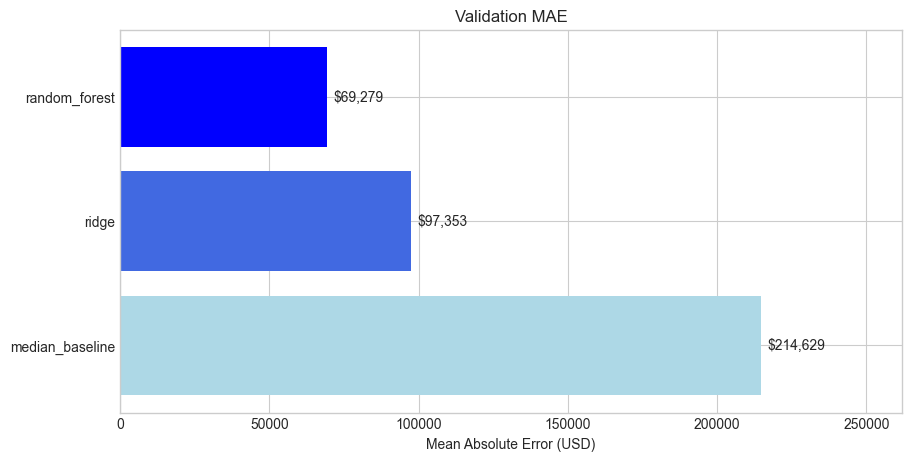

In [8]:
begin_stage('validation_diagnostics')
validation_predictions = prediction_table(
    parts['validation'], validation_predictions_by_model[selected_name], id_sets['train']
)
SEGMENTS = ['price_segment', 'zipcode', 'waterfront', 'property_history']
validation_segments = {group: segment_metrics(validation_predictions, group) for group in SEGMENTS}
display(validation_segments['price_segment'].round(2))
display(validation_segments['waterfront'].round(2))
display(validation_segments['zipcode'].head(10).round(2))

fig_validation, ax = plt.subplots(figsize = (9, 4.5), constrained_layout = True)
chart = validation_metrics.sort_values('MAE_USD', ascending = False)
bars = ax.barh(chart['model'], chart['MAE_USD'], color = ['lightblue', 'royalblue', 'blue'])
ax.bar_label(bars, labels = [f'${value:,.0f}' for value in chart['MAE_USD']], padding = 5)
ax.set_xlim(0, chart['MAE_USD'].max() * 1.22)
ax.set(title = 'Validation MAE', xlabel = 'Mean Absolute Error (USD)', ylabel = '')
display(fig_validation)
plt.close(fig_validation)
COMPLETED.add('validation_diagnostics')

## 9. Explain Validation Behavior with Permutation Importance

,feature,MAE_increase_USD,shuffle_std_USD
0,lat,104814.48,1547.41
1,sqft_living,69342.48,842.47
2,grade,41256.11,730.46
3,long,29621.89,1452.30
4,house_age_at_sale_years,6945.92,233.04
5,sqft_lot,5075.89,153.78
6,view,4043.44,36.20
7,waterfront,2579.06,424.32
8,zipcode,2460.04,288.51
9,sqft_above,2022.30,546.52


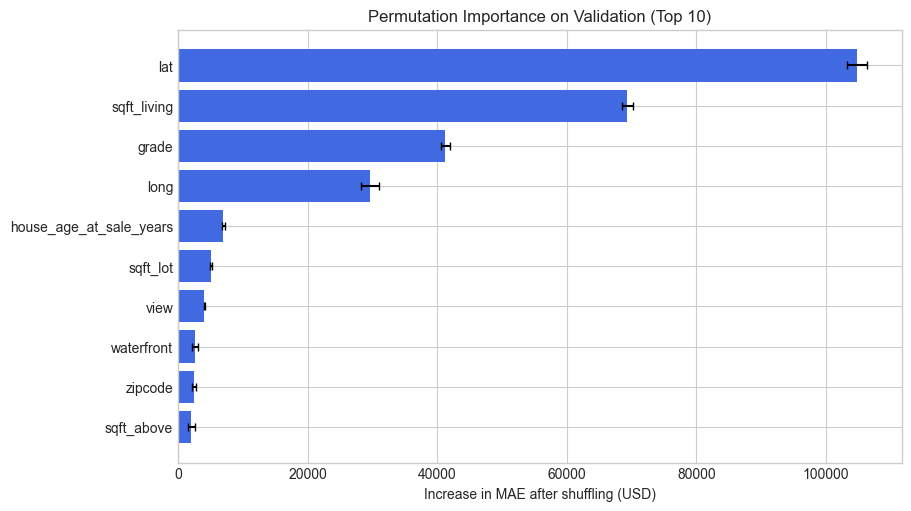

In [9]:
begin_stage('importance')
fig_importance = None
if selected_name == 'median_baseline':
    importance_table = pd.DataFrame(columns = ['feature', 'MAE_increase_USD', 'shuffle_std_USD'])
    print('Median baseline selected: no feature importance to interpret.')
else:
    importance = permutation_importance(
        fitted_candidates[selected_name], X_validation, y_validation,
        scoring = 'neg_mean_absolute_error', n_repeats = 3, random_state = SEED, n_jobs = 1
    )
    importance_table = pd.DataFrame({
        'feature': FEATURES, 'MAE_increase_USD': importance.importances_mean,
        'shuffle_std_USD': importance.importances_std
    }).sort_values('MAE_increase_USD', ascending = False).reset_index(drop = True)
    display(importance_table.round(2))
    plot_data = importance_table.head(10).sort_values('MAE_increase_USD')
    fig_importance, ax = plt.subplots(figsize = (9, 5), constrained_layout = True)
    ax.barh(plot_data['feature'],
            plot_data['MAE_increase_USD'],
            xerr = plot_data['shuffle_std_USD'],
            color = 'royalblue',
            capsize = 3
            )
    ax.axvline(0, color = 'orange', linewidth = 0.8)
    ax.set(title = 'Permutation Importance on Validation (Top 10)', xlabel = 'Increase in MAE after shuffling (USD)', ylabel = '')
    display(fig_importance)
    plt.close(fig_importance)
COMPLETED.add('importance')

## 10. Refit the Selected Model, then Evaluate Test

In [10]:
begin_stage('test')
require(selected_name == selection_record['selected_model'] == str(validation_metrics.iloc[0]['model']), 'The validation selection changed.')
development = pd.concat([parts['train'], parts['validation']], axis = 0)
X_development, y_development = development[FEATURES], development[TARGET]
require(len(development) == 16861 and development['date'].max() < TEST_START, 'Final fitting data must exclude the test period.')
require(not set(development['source_row']) & set(parts['test']['source_row']), 'A test transaction entered the fitting data.')
final_pipeline = clone(candidates[selected_name]).fit(X_development, y_development)
final_baseline = (final_pipeline if selected_name == 'median_baseline' else clone(candidates['median_baseline']).fit(X_development, y_development))
X_test, y_test = parts['test'][FEATURES], parts['test'][TARGET]
test_prediction = final_pipeline.predict(X_test)
test_baseline_prediction = final_baseline.predict(X_test)
test_rows = [{
    'role': 'selected_model', 
    'model': selected_name,
    'fit_rows': len(development),
    **regression_metrics(y_test, test_prediction)
}]
if selected_name != 'median_baseline':
    test_rows.append({
        'role': 'reference_baseline',
        'model': 'median_baseline',
        'fit_rows': len(development),
        **regression_metrics(y_test, test_baseline_prediction)
    })
test_metrics = pd.DataFrame(test_rows)
baseline_test_mae = float(mean_absolute_error(y_test, test_baseline_prediction))
test_metrics['MAE_improvement_vs_median_pct'] = (
    100 * (baseline_test_mae - test_metrics['MAE_USD']) / baseline_test_mae
)
display(test_metrics.round(3))
print('Test results are for reporting, not further model selection.')
COMPLETED.add('test')

,role,model,fit_rows,n,MAE_USD,RMSE_USD,R2,MedAE_USD,negative_predictions,MAE_improvement_vs_median_pct
0,selected_model,random_forest,16861,4752,76958.426,139854.340,0.858,44465.896,0,66.041
1,reference_baseline,median_baseline,16861,4752,226622.194,385509.104,-0.081,149075.000,0,0.000


Test results are for reporting, not further model selection.


## 11. Inspect Final Errors, Including Repeat-Sale Overlap

,price_segment,n,MAE_USD,RMSE_USD,R2,MedAE_USD,negative_predictions,mean_residual_USD,low_sample_n_lt_30
0,above_train_p90,527,245791.07,355499.64,0.60,178502.09,0,186132.54,False
1,train_median_to_p90,1944,72554.02,97886.63,0.28,56761.01,0,38970.84,False
2,at_or_below_train_median,2281,41705.19,58162.08,0.45,30335.53,0,2801.82,False


,property_history,n,MAE_USD,RMSE_USD,R2,MedAE_USD,negative_predictions,mean_residual_USD,low_sample_n_lt_30
0,seen_in_fit,98,108627.94,141829.62,0.78,77575.73,0,106770.31,False
1,unseen_in_fit,4654,76291.56,139812.45,0.86,43847.25,0,36480.15,False


,waterfront,n,MAE_USD,RMSE_USD,R2,MedAE_USD,negative_predictions,mean_residual_USD,low_sample_n_lt_30
0,1.0,35,478327.74,607274.05,0.64,437632.78,0,357872.09,False
1,0.0,4717,73980.28,130261.34,0.86,44094.79,0,35555.77,False


,source_row,date,zipcode,actual_price_usd,predicted_price_usd,residual_usd
1315,1316,2015-04-13,98040,5300000.0,3144882.87,2155117.13
12370,12371,2015-05-06,98006,4210000.0,2346219.03,1863780.97
10446,10447,2015-05-08,98112,3400000.0,1906014.89,1493985.11
5449,5450,2015-05-01,98006,2850000.0,1360904.83,1489095.17
19684,19685,2015-04-29,98034,2210000.0,930124.58,1279875.42
18482,18483,2015-05-11,98004,3650000.0,2487992.38,1162007.62
13967,13968,2015-03-03,98033,3400000.0,2264873.68,1135126.32
20154,20155,2015-03-04,98107,2950000.0,1855446.58,1094553.42
20460,20461,2015-04-02,98004,3350000.0,2281399.52,1068600.48
1448,1449,2015-04-13,98004,5350000.0,4339747.53,1010252.47


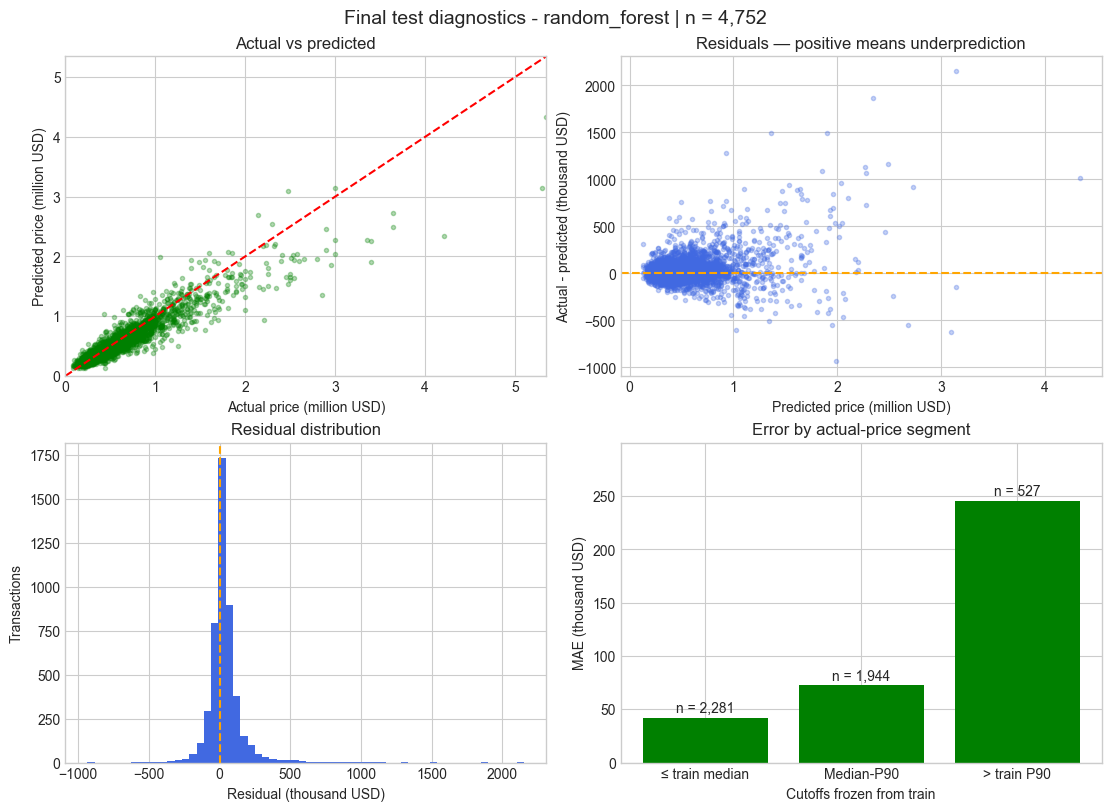

In [11]:
begin_stage('test_diagnostics')
test_predictions = prediction_table(parts['test'], test_prediction, set(development['id']))
test_predictions['baseline_prediction_usd'] = test_baseline_prediction
test_segments = {group: segment_metrics(test_predictions, group) for group in SEGMENTS}
display(test_segments['price_segment'].round(2))
display(test_segments['property_history'].round(2))
display(test_segments['waterfront'].round(2))
display(test_predictions.nlargest(10, 'absolute_error_usd')[[
    'source_row', 'date', 'zipcode', 'actual_price_usd', 'predicted_price_usd', 'residual_usd'
]].round(2))

fig_test, axes = plt.subplots(2, 2, figsize = (11, 8), constrained_layout=True)
actual = test_predictions['actual_price_usd'].to_numpy()
predicted = test_predictions['predicted_price_usd'].to_numpy()
residual = test_predictions['residual_usd'].to_numpy()
limit_low = min(0.0, actual.min(), predicted.min()) / 1e6
limit_high = max(actual.max(), predicted.max()) / 1e6
axes[0, 0].scatter(actual / 1e6, predicted / 1e6, s = 9, alpha = 0.30, color = 'green')
axes[0, 0].plot([limit_low, limit_high], [limit_low, limit_high], '--', color = 'red')
axes[0, 0].set(title = 'Actual vs predicted', xlabel = 'Actual price (million USD)',
               ylabel = 'Predicted price (million USD)', xlim = (limit_low, limit_high),
               ylim = (limit_low, limit_high))
axes[0, 1].scatter(predicted / 1e6, residual / 1e3, s = 9, alpha = 0.30, color = 'royalblue')
axes[0, 1].axhline(0, color='orange', linestyle='--')
axes[0, 1].set(title = 'Residuals — positive means underprediction', xlabel = 'Predicted price (million USD)', ylabel = 'Actual - predicted (thousand USD)')
axes[1, 0].hist(residual / 1e3, bins = 60, color = 'royalblue')
axes[1, 0].axvline(0, color = 'orange', linestyle = '--')
axes[1, 0].set(title = 'Residual distribution', xlabel = 'Residual (thousand USD)', ylabel = 'Transactions')
price_plot = test_segments['price_segment'].set_index('price_segment').reindex([
    'at_or_below_train_median', 'train_median_to_p90', 'above_train_p90'
])
axes[1, 1].bar(['≤ train median', 'Median-P90', '> train P90'],
                price_plot['MAE_USD'] / 1e3, color='green')
for i, row in enumerate(price_plot.itertuples()):
    axes[1, 1].annotate(f'n = {int(row.n):,}', (i, row.MAE_USD / 1e3),
                       xytext = (0, 4), textcoords = 'offset points', ha = 'center')
axes[1, 1].margins(y = 0.22)
axes[1, 1].set(title = 'Error by actual-price segment', xlabel = 'Cutoffs frozen from train', ylabel = 'MAE (thousand USD)')
fig_test.suptitle(f'Final test diagnostics - {selected_name} | n = {len(y_test):,}', fontsize = 14)
display(fig_test)
plt.close(fig_test)
COMPLETED.add('test_diagnostics')

## 12. Reports

In [12]:
begin_stage('export')
require(notebook_code_sha256() == SAVED_CODE_SHA256,
        'Saved notebook code changed during this run. Save, restart and rerun all cells.')
for name, path in [('raw_csv', RAW_PATH), ('clean_reference', REFERENCE_PATH),
                   ('audit_manifest', AUDIT_PATH), ('step2_report', STEP2_PATH)]:
    require(sha256_file(path) == INPUT_HASHES[name], f'Input changed during training: {name}')
require({p.name: sha256_file(p) for p in sorted((ROOT / 'sql').glob('*.sql'))} == sql_hashes,
        'SQL files changed during this run.')

run_at = datetime.now(timezone.utc).isoformat()
limitations = [
    'Historical King County transactions from 2014-2015; not a current-market valuation.',
    'Full-file EDA and KPI inspection occurred before this modeling split.',
    'Chronological split permits property-ID overlap; not an ID-disjoint benchmark.',
    'Historical feature availability at listing time is not established by the source.',
    'Age features assume a known valuation date; use the same definition at prediction time.',
    'Price-segment and importance diagnostics are descriptive, not causal or uncertainty intervals.',
    'Fixed initial candidates; no claim of optimal hyperparameters or production readiness.'
]
feature_schema = {
    'target': TARGET, 'target_unit': 'USD', 'feature_order': FEATURES,
    'numeric_features': NUMERIC_FEATURES, 'categorical_features': CATEGORICAL_FEATURES,
    'categorical_input': 'zipcode: five-character string; unseen categories are ignored by the encoder',
    'numeric_input': 'finite floats or np.nan; no infinity',
    'missing_policy': 'median imputation with missing indicators, learned only within the fitted pipeline',
    'age_policy': 'valuation year minus audited built/renovation year; future years masked to NaN',
    'renovation_policy': 'was_renovated = 0 for recorded year 0; years_since_renovation=NaN then; unknown year remains NaN',
    'excluded_columns': sorted(set(sales.columns) - set(FEATURES) - {TARGET})
}

def save_json(path, value):
    Path(path).write_text(json.dumps(value, indent = 2, ensure_ascii = False, allow_nan = False), encoding = 'utf-8')

save_json(REPORT_DIR / 'modeling_report.json', {'status': 'export_in_progress'})
tables = {
    'split_assignments.csv': split_assignments,
    'feature_audit.csv': feature_audit.reset_index(names='feature'),
    'validation_metrics.csv': validation_metrics,
    'test_metrics.csv': test_metrics,
    'validation_predictions.csv': validation_predictions,
    'test_predictions.csv': test_predictions,
    'validation_permutation_importance.csv': importance_table
}
for split_name, groups in [('validation', validation_segments), ('test', test_segments)]:
    for group, table in groups.items():
        tables[f'{split_name}_errors_by_{group}.csv'] = table
for filename, table in tables.items():
    table.to_csv(REPORT_DIR / filename, index = False)
save_json(REPORT_DIR / 'split_manifest.json', split_manifest)
save_json(REPORT_DIR / 'feature_schema.json', feature_schema)
figures = {'validation_mae.png': fig_validation, 'test_diagnostics.png': fig_test}
if fig_importance is not None:
    figures['validation_permutation_importance.png'] = fig_importance
for filename, figure in figures.items():
    figure.savefig(REPORT_DIR / filename, dpi = 160, facecolor = 'white')

MODEL_PATH = MODEL_DIR / 'property_price_pipeline.joblib'
joblib.dump(final_pipeline, MODEL_PATH, compress=3)
reloaded_pipeline = joblib.load(MODEL_PATH)
np.testing.assert_allclose(reloaded_pipeline.predict(X_test.iloc[:20]),
                           test_prediction[:20], rtol = 1e-10, atol = 1e-6)
model_metadata = {
    'selected_model': selected_name,
    'fitted_on': 'train + validation only', 'fit_rows': len(development),
    'fit_last_date': development['date'].max().date().isoformat(),
    'source_sha256': EXPECTED_SOURCE, 'saved_notebook_code_sha256': SAVED_CODE_SHA256,
    'python': platform.python_version(), 'packages': PACKAGES,
    'seed': SEED, 'model_parameters': model_specs[selected_name],
    'feature_schema': feature_schema, 'limitations': limitations,
    'model_sha256': sha256_file(MODEL_PATH), 'reload_predictions_match': True
}
save_json(MODEL_DIR / 'model_metadata.json', model_metadata)
output_paths = [REPORT_DIR / name for name in tables]
output_paths += [REPORT_DIR / 'split_manifest.json', REPORT_DIR / 'feature_schema.json']
output_paths += [REPORT_DIR / name for name in figures]
output_paths += [MODEL_PATH, MODEL_DIR / 'model_metadata.json']
modeling_report = {
    'status': 'completed_and_reloaded',
    'database': database_info, 'input_sha256': INPUT_HASHES, 'sql_sha256': sql_hashes,
    'saved_notebook_code_sha256': SAVED_CODE_SHA256,
    'python': platform.python_version(), 'packages': PACKAGES,
    'rows_verified': len(sales), 'clean_columns_verified': len(clean_columns),
    'split_manifest': split_manifest, 'selection': selection_record,
    'validation_metrics': validation_metrics.to_dict(orient='records'),
    'test_metrics': test_metrics.to_dict(orient='records'),
    'reload_predictions_match': True, 'limitations': limitations,
    'output_sha256': {path.relative_to(ROOT).as_posix(): sha256_file(path) for path in output_paths}
}
save_json(REPORT_DIR / 'modeling_report.json', modeling_report)
print('Saved:', MODEL_PATH.relative_to(ROOT))
print('Saved reports to:', REPORT_DIR.relative_to(ROOT))
print('Status:', modeling_report['status'])
COMPLETED.add('export')

Saved: models\property_price_pipeline.joblib
Saved reports to: reports\modeling
Status: completed_and_reloaded


## 13. Reload and Predict Using a Feature-Only Example

In [13]:
begin_stage('prediction_example')
example_features = parts['test'].loc[:, FEATURES].head(5).copy()
require(TARGET not in example_features.columns, 'Target must not enter prediction inputs.')
example_output = parts['test'][['source_row', 'zipcode']].head(5).copy()
example_output['predicted_price_usd'] = reloaded_pipeline.predict(example_features)
display(example_output.round(2))
COMPLETED.add('prediction_example')

,source_row,zipcode,predicted_price_usd
8,9,98146,278472.71
9,10,98038,320292.27
10,11,98007,712452.66
14,15,98107,559555.66
19,20,98003,210150.76


## 14. Results and Interpretation

### Model selection and final test

The chronological split contains 14,633 training transactions before 1 January 2015, 2,228 validation transactions in January – February 2015, and 4,752 test transactions from March 2015. Selection used validation MAE only:

| Candidate | Validation MAE (USD) |
|---|---:|
| Random Forest | 69,278.76 |
| Ridge regression | 97,352.88 |
| Median baseline | 214,628.93 |

Random Forest achieved the lowest validation MAE. The selected pipeline was refitted on all 16,861 training and validation transactions before test evaluation. The median baseline was refitted on the same development data.

| Test model | MAE (USD) | RMSE (USD) | R² | Median absolute error (USD) |
|---|---:|---:|---:|---:|
| Random Forest | 76,958.43 | 139,854.34 | 0.8578 | 44,465.90 |
| Median baseline | 226,622.19 | 385,509.10 | -0.0807 | 149,075.00 |

Random Forest reduces test MAE by **66.04%** relative to the baseline. MAE is the average absolute dollar error; individual predictions can be much farther from the actual price. Neither the MAE reduction nor R² is a percentage of correct predictions. RMSE being substantially larger than MAE reflects some large errors.

### Where the model struggles

Price thresholds are fixed from training data: the median is $450,000 and the 90th percentile is $883,000. These segments use actual prices for retrospective error analysis; they are not predictors or routing rules for new properties.

| Test segment | Transactions | MAE (USD) |
|---|---:|---:|
| Actual price ≤ $450,000 | 2,281 | 41,705.19 |
| $450,000 < actual price ≤ $883,000 | 1,944 | 72,554.02 |
| Actual price > $883,000 | 527 | 245,791.07 |
| Waterfront | 35 | 478,327.74 |
| Non-waterfront | 4,717 | 73,980.28 |

High-price and waterfront properties have much larger absolute dollar errors. Their positive mean residuals, defined as actual price minus predicted price, indicate underprediction on average. Waterfront evaluation uses only 35 transactions, so this estimate should be interpreted cautiously. The price and waterfront rows are separate breakdowns; they are not five mutually exclusive groups. Dollar-error differences do not establish differences in relative error or causal effects.

Validation permutation importance ranks latitude, living area, grade, and longitude highest. These scores describe the fitted model's dependence on a feature in this validation sample; they do not establish causation.

### Scope and limitations

- The data cover historical King County sales from May 2014 through May 2015, with partial first and last months.
- Full-file exploration preceded the modeling experiment. The test period was excluded from fitting and selection, but was not entirely unseen during exploration.
- Property IDs overlap across chronological periods. Of the 4,752 test transactions, 98 belong to properties present in the training/validation data. Evaluation targets later transactions rather than a strictly unseen-property benchmark.
- Historical availability of every attribute at listing time is not established. Derived ages assume a known valuation year and the audited handling of missing or inconsistent years.
- The experiment compares fixed median, Ridge, and Random Forest configurations; it does not establish optimal hyperparameters.
- No prediction intervals, current-market performance, geographic transfer, or production appraisal validation are provided.

### Conclusion and dashboard connection

Random Forest provides a substantial improvement over the median-price baseline for later transactions in this historical sample. Performance varies considerably by price band and waterfront status, so aggregate metrics should be read alongside segment diagnostics.

The Power BI report uses the 21,613 audited transactions and saved predictions for the 4,752 test rows. It presents sales activity, location-level median prices, and test errors. Prediction fields remain blank for training and validation rows. The static note labelled **“Overall test, unfiltered”** describes the full test set, while card and chart measures respond to slicers.

The supplied pipeline, evaluation reports, and dashboard document the completed experiment. Any future model changes should be selected using a documented validation plan rather than the observed test score.
